Import stability package

(from [https://github.com/nogueirs/JMLR2018](https://github.com/nogueirs/JMLR2018))

In [25]:
import sys
sys.path.append('../../')
from fseval.analysis.lib import stability
stability.getStability

<function fseval.analysis.lib.stability.getStability(Z)>

Load binary subsets data

In [80]:
import pandas as pd
from tqdm import tqdm
datacol = pd.read_csv('./data/benchmark_24-replicas.csv')
result_dirs = ['../../results/11714894_subsets', '../../results/11824789']
chunks = []
for _, dataset in tqdm(datacol.iterrows(), total=len(datacol)):
    for result_dir in result_dirs:
        statpath = os.path.join(result_dir, 'binary_subsets', dataset.path + '.csv')
        if os.path.exists(statpath):
            chunks.append(pd.read_csv(statpath))
bindata = pd.concat(chunks)
del chunks
print('bindata successfully collected.')

100%|██████████| 1828/1828 [00:09<00:00, 182.99it/s]
bindata successfully collected.


Compute stabilities

In [85]:
import numpy as np
import time

def compute_stability(replicas):
    to_int = lambda array: list(map(int, array))
    Z = replicas.str.split(pat=',').map(to_int).values
    Z = np.array(Z.tolist()) # make numpy appreciate both dimensions properly.
    M, d = Z.shape
    if M == 1: # theres only 1 replica available. stability can't be computed.
        return { 'stability': np.nan, 'lower': np.nan, 'upper': np.nan }
    return stability.confidenceIntervals(Z)

def split_cols(row):
    res = row.binary_subset
    row['stability'] = res['stability']
    row['stability_lowerconf'] = res['lower']
    row['stability_upperconf'] = res['upper']
    del row['binary_subset']
    return row

s = time.time()
stabdata = bindata\
    .groupby(['description', 'ranking_method'])\
    .agg({ 'binary_subset': compute_stability })\
    .apply(split_cols, axis=1)\
    .reset_index()
print('took {:.5f} seconds'.format(time.time() - s))
stabdata

took 3.76497 seconds


,description,ranking_method,stability,stability_lowerconf,stability_upperconf
0,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.057246,0.027123,0.087370
1,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",FeatBoost,0.448655,0.367090,0.530221
2,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",FeatBoost Deep,0.441990,0.363165,0.520815
3,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",FeatBoost w/1-NN,0.671715,0.538750,0.804680
4,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",MultiSURF,0.059420,0.022764,0.096077
...,...,...,...,...,...
410,"XOR Models [p=20,n=1600,p_=5,h=1]",FeatBoost,0.001242,-0.028607,0.031092
411,"XOR Models [p=20,n=1600,p_=5,h=1]",FeatBoost Deep,0.027505,-0.028653,0.083663
412,"XOR Models [p=20,n=1600,p_=5,h=1]",FeatBoost w/1-NN,0.016812,-0.034711,0.068334
413,"XOR Models [p=20,n=1600,p_=5,h=1]",MultiSURF,0.165217,0.099433,0.231002


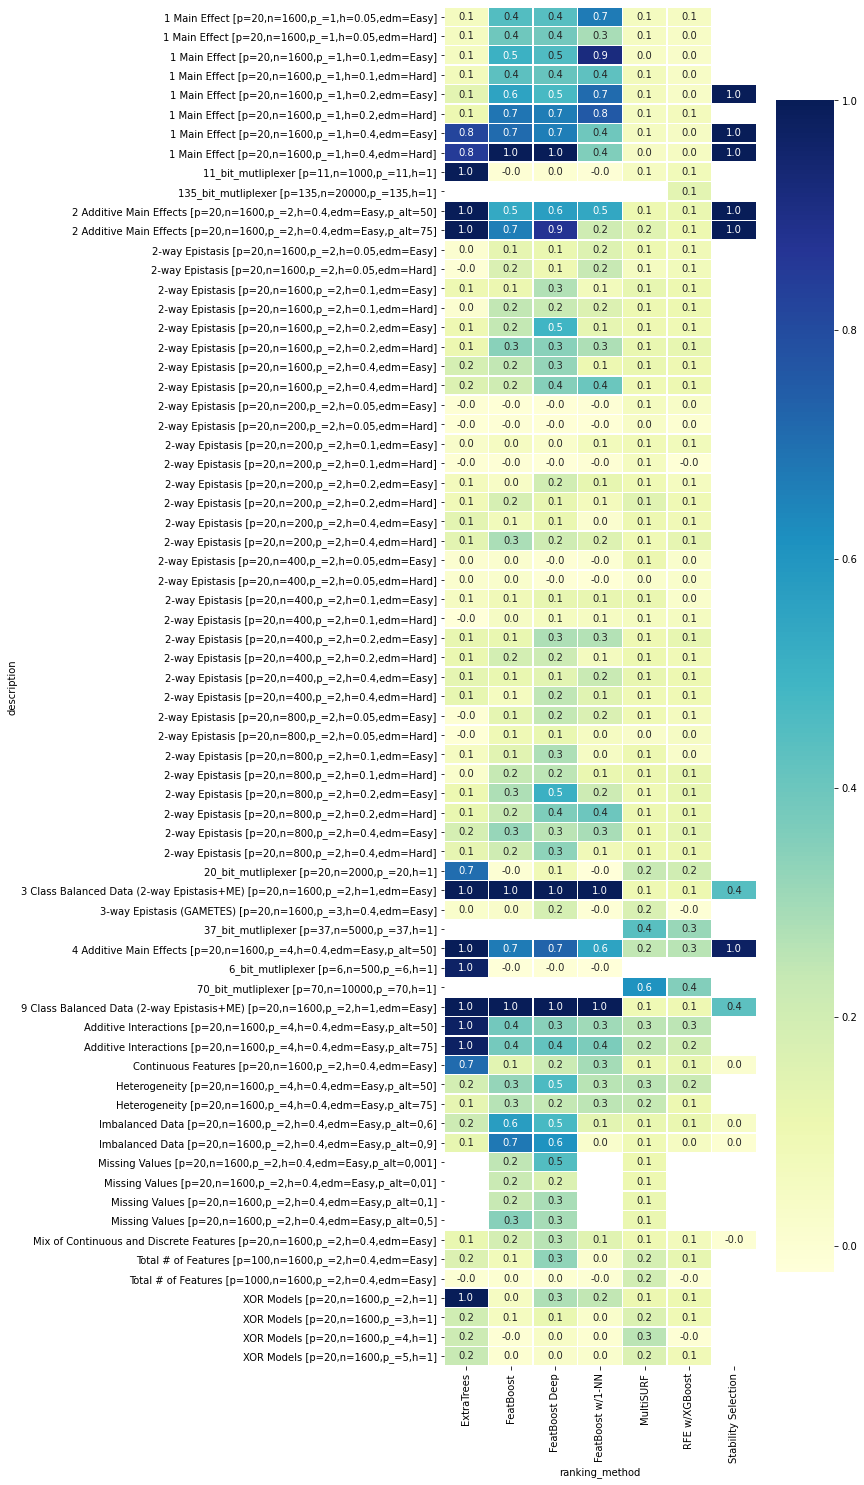

In [91]:
import seaborn as sns
import matplotlib.pyplot as plt
rectangular = pd.pivot_table(stabdata,\
    values='stability',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(rectangular,\
    annot=True, fmt=".1f", linewidths=.5,\
    cmap="YlGnBu", yticklabels=True, ax=ax)